# Study 1 (science funding): main analysis

Writes tables to `tables/` and figures to `plots/`. The manuscript, and `study_comparison/study_comparison.ipynb`, read those files.

**Input:** `data/clean/analysis_data.csv`, produced by `get_data.py`.

## Setup

Moves into this folder, then loads the shared helpers and utility functions.

In [1]:
# Every path in this notebook is relative to the sci_fund_real/ folder. Move there first, so the
# notebook runs whether the kernel starts in sci_fund_real/ or in the repo root.
import os
from pathlib import Path
if not Path("hte_grf.R").exists() and Path("sci_fund_real/hte_grf.R").exists():
    os.chdir("sci_fund_real")

import sys
sys.path.insert(0, os.path.abspath('.'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import ttest_ind, spearmanr
import pingouin as pg

from helpers import (
    make_aesthetic, cat_stats, array_stats, clean_vars,
    cat_stats_table, age_bands, format_p_value, format_p_value_stars,
    add_stars_to_df,
)
from statsmodels_handler import StatsmodelsHandler

####################
# Utility functions
####################

def z_score(series):
    return (series - series.mean()) / series.std(ddof=0)

def cohens_d(group_a, group_b):
    group_a, group_b = group_a.dropna(), group_b.dropna()
    n_a, n_b = len(group_a), len(group_b)
    if n_a < 2 or n_b < 2:
        return np.nan
    sd_a, sd_b = group_a.std(ddof=1), group_b.std(ddof=1)
    pooled_sd = np.sqrt(((n_a - 1)*sd_a**2 + (n_b - 1)*sd_b**2) / (n_a + n_b - 2))
    return (group_a.mean() - group_b.mean()) / pooled_sd

def bootstrap_cohens_d_se(group_a, group_b, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    a, b = group_a.dropna().values, group_b.dropna().values
    if len(a) < 2 or len(b) < 2:
        return np.nan
    boot_ds = [
        cohens_d(pd.Series(rng.choice(a, len(a), replace=True)),
                 pd.Series(rng.choice(b, len(b), replace=True)))
        for _ in range(n_boot)
    ]
    return np.std(boot_ds, ddof=1)

def extract_number(value):
    if pd.isna(value):
        return np.nan
    import re as _re
    m = _re.search(r"-?\d+(\.\d+)?", str(value))
    return float(m.group()) if m else np.nan


## Load data

**Input:** `data/clean/analysis_data.csv`. Caps `ac_prop_ai_words` at 1.

In [2]:
####################
# Load clean data
####################

df = pd.read_csv("data/clean/analysis_data.csv")
# ac_prop_ai_words exceeds 1 for a handful of participants; cap it so the
# proportion is well defined wherever it is used downstream.
if "ac_prop_ai_words" in df.columns:
    df["ac_prop_ai_words"] = df["ac_prop_ai_words"].clip(upper=1)

LOW_FAM_CUTOFF = 2

####################
# Report N and low-familiarity breakdown
####################

print(f"N = {len(df)}")
print(f"treat_status:\n{df['treat_status'].value_counts().to_string()}")
low_n = (df['familiar'] <= LOW_FAM_CUTOFF).sum()
print(f"\nLow familiarity (familiar <= {LOW_FAM_CUTOFF}): {low_n} / {len(df)} ({100*low_n/len(df):.1f}%)")
print(f"High familiarity: {len(df)-low_n} / {len(df)} ({100*(len(df)-low_n)/len(df):.1f}%)")


N = 1007
treat_status:
treat_status
placebo     343
treat       333
vignette    331

Low familiarity (familiar <= 2): 488 / 1007 (48.5%)
High familiarity: 519 / 1007 (51.5%)


# Treatment effects

## Subsamples

**Computation:** defines the full and familiarity subsamples used below.

In [3]:
####################
# Subsamples (used throughout)
####################

subsamples = {
    "Full Sample":    df.copy(),
    "Low Knowledge":  df[df["familiar"] <= LOW_FAM_CUTOFF].copy(),
    "High Knowledge": df[df["familiar"] >  LOW_FAM_CUTOFF].copy(),
}
for sdf in subsamples.values():
    sdf["treat_status"] = pd.Categorical(
        sdf["treat_status"], categories=["treat", "vignette", "placebo"]
    )

OUTCOMES = {
    "closeness_index": "Psychological Closeness",
    "attitude_index":  "Attitudes",
}
COND_LABELS = {"treat": "AIM", "vignette": "Vignette", "placebo": "Placebo"}
CONTRASTS = {
    "C(treat_status)[T.vignette]": "AIM vs. Vignette",
    "C(treat_status)[T.placebo]":  "AIM vs. Placebo",
}


## Main effects

**Computation:** AIM-minus-control effects on closeness and attitudes, overall and by familiarity, at both preregistered familiarity cutoffs, with sharpened q-values over the 12 contrasts at each cutoff.


CUTOFF=2  SAMPLE: Full Sample  (N=1007)

  Psychological Distance  |  R2=0.107  N=1007
  AIM vs. Vignette: beta=0.36, SE=0.07, 95% CI [0.22, 0.49], t=-5.27, p = 1.4e-07, sharpened q=0.00100, 1.3552148028443237e-07
  AIM vs. Placebo: beta=0.80, SE=0.07, 95% CI [0.66, 0.94], t=-10.96, p = 6.2e-28, sharpened q=0.00100, 6.249362936443215e-28

  Attitudes  |  R2=0.004  N=1007
  AIM vs. Vignette: beta=0.16, SE=0.08, 95% CI [0.00, 0.32], t=-2.00, p = .05, sharpened q=0.03400, 0.04548633391071867
  AIM vs. Placebo: beta=0.10, SE=0.07, 95% CI [-0.05, 0.24], t=-1.31, p = .19, sharpened q=0.07100, 0.19095861433905437

CUTOFF=2  SAMPLE: Low Knowledge  (N=488)

  Psychological Distance  |  R2=0.158  N=488
  AIM vs. Vignette: beta=0.55, SE=0.11, 95% CI [0.35, 0.76], t=-5.20, p = 2.0e-07, sharpened q=0.00100, 2.0044571700100845e-07
  AIM vs. Placebo: beta=1.09, SE=0.11, 95% CI [0.87, 1.31], t=-9.76, p = 1.7e-22, sharpened q=0.00100, 1.6529203191833594e-22

  Attitudes  |  R2=0.018  N=488
  AIM vs. V

/var/folders/4r/zf8yg_9n3qn26k_y7w56_gqr0000gp/T/ipykernel_47619/1121755622.py:200: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(left=0.2, wspace=0.25, hspace=0.30)


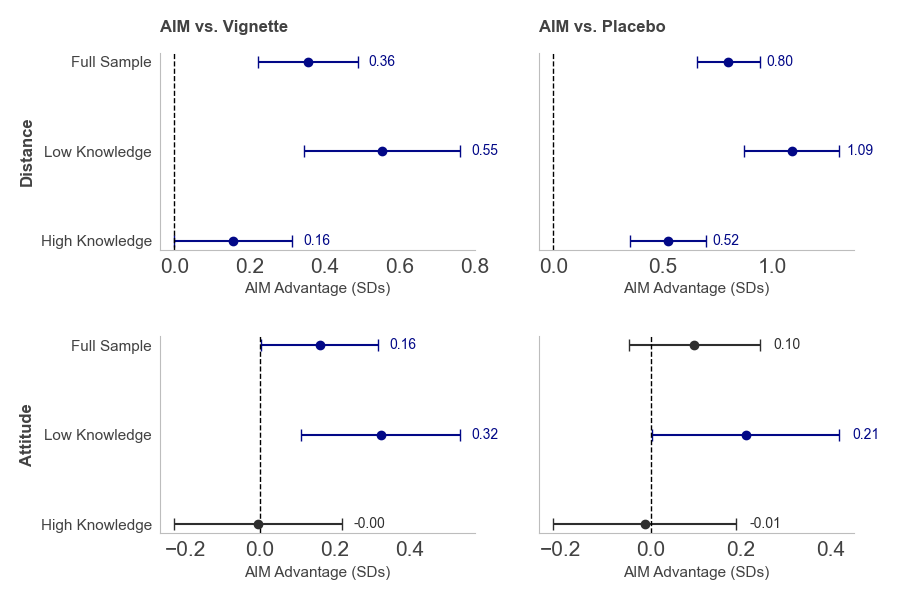


CUTOFF=3  SAMPLE: Full Sample  (N=1007)

  Psychological Distance  |  R2=0.107  N=1007
  AIM vs. Vignette: beta=0.36, SE=0.07, 95% CI [0.22, 0.49], t=-5.27, p = 1.4e-07, sharpened q=0.00100, 1.3552148028443237e-07
  AIM vs. Placebo: beta=0.80, SE=0.07, 95% CI [0.66, 0.94], t=-10.96, p = 6.2e-28, sharpened q=0.00100, 6.249362936443215e-28

  Attitudes  |  R2=0.004  N=1007
  AIM vs. Vignette: beta=0.16, SE=0.08, 95% CI [0.00, 0.32], t=-2.00, p = .05, sharpened q=0.04100, 0.04548633391071867
  AIM vs. Placebo: beta=0.10, SE=0.07, 95% CI [-0.05, 0.24], t=-1.31, p = .19, sharpened q=0.10600, 0.19095861433905437

CUTOFF=3  SAMPLE: Low Knowledge  (N=662)

  Psychological Distance  |  R2=0.147  N=662
  AIM vs. Vignette: beta=0.47, SE=0.09, 95% CI [0.30, 0.65], t=-5.28, p = 1.3e-07, sharpened q=0.00100, 1.2952241912839238e-07
  AIM vs. Placebo: beta=1.00, SE=0.09, 95% CI [0.82, 1.19], t=-10.76, p = 5.5e-27, sharpened q=0.00100, 5.504091545404614e-27

  Attitudes  |  R2=0.010  N=662
  AIM vs. V

/var/folders/4r/zf8yg_9n3qn26k_y7w56_gqr0000gp/T/ipykernel_47619/1121755622.py:200: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(left=0.2, wspace=0.25, hspace=0.30)


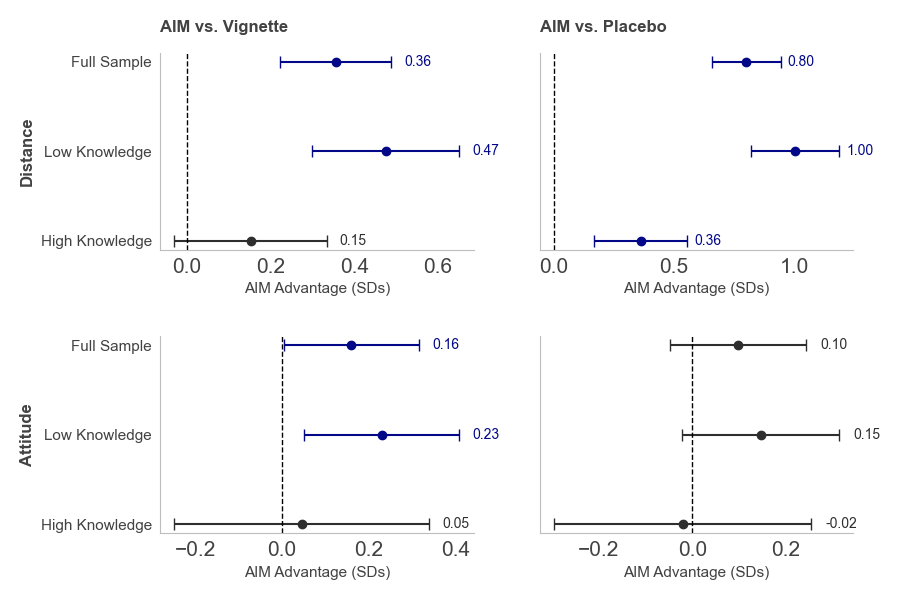

In [4]:
from sharp_q_values import compute_q
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels_handler import StatsmodelsHandler
from helpers import format_p_value, make_aesthetic

SHOW_RAW_DIFF = False  # also plot raw mean differences alongside regression estimates

OUTCOME_LABELS = {
    "closeness_index": "Psychological Distance",
    "attitude_index": "Attitudes",
}
OUTCOME_SHORT = {
    "closeness_index": "Distance",
    "attitude_index": "Attitude",
}
CONTRASTS = {
    "C(treat_status)[T.vignette]": "AIM vs. Vignette",
    "C(treat_status)[T.placebo]":  "AIM vs. Placebo",
}
SAMPLE_ORDER = ["Full Sample", "Low Knowledge", "High Knowledge"]

for LOW_FAM_CUTOFF in [2, 3]:

    ###############
    # Build subsamples
    ###############

    local_subsamples = {
        "Full Sample":    df.copy(),
        "Low Knowledge":  df[df["familiar"] <= LOW_FAM_CUTOFF].copy(),
        "High Knowledge": df[df["familiar"] >  LOW_FAM_CUTOFF].copy(),
    }
    for sdf in local_subsamples.values():
        sdf["treat_status"] = pd.Categorical(
            sdf["treat_status"], categories=["treat", "vignette", "placebo"]
        )

    ###############
    # Fit models
    ###############

    results = {}
    for name, sdf in local_subsamples.items():
        results[name] = {}
        for outcome in ["closeness_index", "attitude_index"]:
            results[name][outcome] = smf.ols(
                f"{outcome} ~ C(treat_status)", data=sdf
            ).fit(cov_type="HC1")

    ###############
    # Print APA stats
    ###############

    ###############
    # Sharpened q-values: the 12 contrasts at this cutoff (3 samples x 2 outcomes x 2 controls) are one family
    ###############

    q_keys = [(s, o, r) for s, outcome_models in results.items()
              for o, m in outcome_models.items() for r in CONTRASTS if r in m.params.index]
    q_sharp = dict( zip( q_keys, compute_q( np.array([results[s][o].pvalues[r] for s, o, r in q_keys]), 0.001, ), ) )
    for sample_name, outcome_dict in results.items():
        n = len(local_subsamples[sample_name])
        print(f"\n{'='*65}")
        print(f"CUTOFF={LOW_FAM_CUTOFF}  SAMPLE: {sample_name}  (N={n})")
        print(f"{'='*65}")
        for outcome, mod in outcome_dict.items():
            print(f"\n  {OUTCOME_LABELS[outcome]}  |  R2={mod.rsquared:.3f}  N={int(mod.nobs)}")
            for raw_name, label in CONTRASTS.items():
                if raw_name not in mod.params.index:
                    continue
                beta    = -mod.params[raw_name]
                se      =  mod.bse[raw_name]
                t_stat  =  mod.tvalues[raw_name]
                pval    =  mod.pvalues[raw_name]
                ci      =  mod.conf_int().loc[raw_name]
                ci_lo, ci_hi = -ci[1], -ci[0]
                p_str = format_p_value(pval)
                print(
                    f"  {label}: beta={beta:.2f}, SE={se:.2f}, "
                    f"95% CI [{ci_lo:.2f}, {ci_hi:.2f}], t={t_stat:.2f}, {p_str}, "
                    f"sharpened q={q_sharp[(sample_name, outcome, raw_name)]:.5f}, {pval}"
                )

    ###############
    # Build forest data
    ###############

    forest_rows = []
    for sample_name in SAMPLE_ORDER:
        for outcome, mod in results[sample_name].items():
            if outcome not in OUTCOME_SHORT:
                continue
            for raw_name, contrast_label in CONTRASTS.items():
                if raw_name not in mod.params.index:
                    continue
                beta = -mod.params[raw_name]
                ci = mod.conf_int().loc[raw_name]
                forest_rows.append({
                    "sample":   sample_name,
                    "outcome":  OUTCOME_SHORT[outcome],
                    "contrast": contrast_label,
                    "beta":     beta,
                    "ci_lo":    -ci[1],
                    "ci_hi":    -ci[0],
                    "sig":      mod.pvalues[raw_name] < 0.05,
                    "kind":     "Regression-based",
                })
    # Raw mean differences
    if SHOW_RAW_DIFF:
        from scipy.stats import ttest_ind as _ttest
        _cmap = {"C(treat_status)[T.vignette]": "vignette",
                 "C(treat_status)[T.placebo]":  "placebo"}
        for sample_name, sdf in local_subsamples.items():
            for outcome, short in OUTCOME_SHORT.items():
                treat_vals = sdf[sdf["treat_status"] == "treat"][outcome].dropna()
                for raw_name, contrast_label in CONTRASTS.items():
                    comp_cond = _cmap[raw_name]
                    comp_vals = sdf[sdf["treat_status"] == comp_cond][outcome].dropna()
                    diff = treat_vals.mean() - comp_vals.mean()
                    se   = np.sqrt(treat_vals.sem()**2 + comp_vals.sem()**2)
                    forest_rows.append({
                        "sample":   sample_name,
                        "outcome":  short,
                        "contrast": contrast_label,
                        "beta":     diff,
                        "ci_lo":    diff - 1.96 * se,
                        "ci_hi":    diff + 1.96 * se,
                        "sig":      _ttest(treat_vals, comp_vals).pvalue < 0.05,
                        "kind":     "Raw difference",
                    })
    forest_df = pd.DataFrame(forest_rows)

    ###############
    # Plot
    ###############

    pal = make_aesthetic()
    contrasts = list(CONTRASTS.values())
    outcomes  = list(OUTCOME_SHORT.values())

    fig, axes = plt.subplots(len(outcomes), len(contrasts), figsize=(9, 6), sharey=True)
    axes = np.atleast_2d(axes)

    # y=0 → High Knowledge (bottom), y=1 → Low Knowledge, y=2 → Full Sample (top)
    y_ticks = {"High Knowledge": 0, "Low Knowledge": 1, "Full Sample": 2}
    y_labels = ["High Knowledge", "Low Knowledge", "Full Sample"]
    col_sig = "#444444"
    col_ns  = "#444444"

    for row_i, outcome in enumerate(outcomes):
        for col_i, contrast in enumerate(contrasts):
            ax = axes[row_i, col_i]
            subset = forest_df[
                (forest_df["outcome"] == outcome) &
                (forest_df["contrast"] == contrast)
            ]
            _kinds   = forest_df["kind"].unique().tolist()
            _dodge   = {k: (i - (len(_kinds)-1)/2) * 0.18 for i, k in enumerate(_kinds)}
            _markers = {"Regression-based": "o", "Raw difference": "D"}
            _sig_color   = "#020887"   # blue — significant (palette)
            _insig_color = "#2E2E2E"   # black — not significant
            for _, r in subset.iterrows():
                y    = y_ticks[r["sample"]] + _dodge.get(r["kind"], 0)
                col  = _sig_color if r["sig"] else _insig_color
                mrkr = _markers.get(r["kind"], "o")
                ax.errorbar(
                    r["beta"], y,
                    xerr=[[r["beta"] - r["ci_lo"]], [r["ci_hi"] - r["beta"]]],
                    fmt=mrkr, color=col, ecolor=col, capsize=4, markersize=6, linewidth=1.5,
                )
                if r["kind"] == "Regression-based":
                    ax.text(
                        r["ci_hi"] + 0.03, y, f"{r['beta']:.2f}",
                        va="center", ha="left", fontsize=10, color=col,
                    )
            ax.axvline(0, color="black", linestyle="--", linewidth=1)
            ax.set_yticks([0, 1, 2])
            if col_i == 0:
                ax.set_yticklabels(y_labels, fontsize=11)
                ax.set_ylabel(outcome, fontsize=12, fontweight="bold")
            else:
                ax.tick_params(labelleft=False)
                ax.set_ylabel("")
            ax.set_xlabel("AIM Advantage (SDs)", fontsize=11)
            if row_i == 0:
                ax.set_title(contrast, fontsize=12, fontweight="bold")
            ax.spines[["top", "right"]].set_visible(False)

    if SHOW_RAW_DIFF:
        import matplotlib.lines as mlines
        legend_handles = [
            mlines.Line2D([], [], color="#2E2E2E", marker="o", linestyle="-", markersize=6, label="Regression-based"),
            mlines.Line2D([], [], color="#888888", marker="D", linestyle="-", markersize=6, label="Raw difference"),
        ]
        fig.legend(handles=legend_handles, loc="lower center", ncol=2, fontsize=10,
                   frameon=False, bbox_to_anchor=(0.5, -0.04))
    plt.subplots_adjust(left=0.2, wspace=0.25, hspace=0.30)
    fig.savefig(f"plots/forest_plot_{LOW_FAM_CUTOFF}.pdf", bbox_inches="tight")
    plt.show()


## Balance

**Output:** `tab:balance.tex`

**Computation:** pretreatment covariates by condition, with sharpened q-values.

In [3]:
from scipy.stats import f_oneway, chi2_contingency
import statsmodels.formula.api as smf
from sharp_q_values import compute_q

####################
# Balance table — pre-treatment covariates by condition
# Continuous vars: one-way ANOVA F-test
# Binary/categorical: chi-square
####################

BALANCE_VARS = {
    'age':               ('Age',                       'continuous'),
    'gender_male':       ('Male (\\%)',                  'binary'),
    'educ_num':          ('Education (Recoded 1–8)',    'continuous'),
    'income_num':        ('Income (Recoded 1–7)',       'continuous'),
    'ideology_num':      ('Political Ideology (+ = conservative)', 'continuous'),
    'familiar':          ('Familiarity w/ sci. funding','continuous'),
    'mi_index':          ('Mental imagery',             'continuous'),
    'iri_fa':            ('IRI Fantasy',                'continuous'),
    'iri_pc':            ('IRI Perspective-taking',     'continuous'),
    'iri_pd':            ('IRI Personal distress',      'continuous'),
    'rw_write':          ('Creative writing exp.',      'continuous'),
    'rw_journal':        ('Journaling freq.',           'continuous'),
    'ai_attitude_index': ('AI attitudes',               'continuous'),
}

conditions = ['treat', 'placebo', 'vignette']
rows = []

for col, (label, kind) in BALANCE_VARS.items():
    groups = [df[df['treat_status'] == c][col].dropna() for c in conditions]
    means  = [g.mean() for g in groups]
    sds    = [g.std()  for g in groups]

    if kind == 'binary':
        cell_vals = [f"{g.mean()*100:.1f}\\%" for g in groups]
        # chi-square on counts
        ct = pd.crosstab(df[col], df['treat_status'])
        chi2, p, *_ = chi2_contingency(ct)
        stat_str = f"$\\chi^2$={chi2:.2f}"
    else:
        cell_vals = [f"{m:.2f} ({s:.2f})" for m, s in zip(means, sds)]
        F, p = f_oneway(*groups)
        stat_str = f"F={F:.2f}"

    rows.append({
        'Variable': label,
        'Treat':    cell_vals[0],
        'Placebo':  cell_vals[1],
        'Vignette': cell_vals[2],
        'Test':     stat_str,
        'p':        round(p, 3),
    })

# Party ID comes from Prolific supplementary data, so it is missing for participants without it.
# One row with the share of Democrats / Independents / Republicans in each arm, and one
# chi-square test on the full party-by-arm table among participants with party available.
PARTIES = ['Democrat', 'Independent', 'Republican']
party_df = df.dropna(subset=['pid3'])
party_ct = pd.crosstab(party_df['pid3'], party_df['treat_status']).loc[PARTIES, conditions]
chi2, p, *_ = chi2_contingency(party_ct)
rows.append({
    'Variable': 'Party ID: D / I / R (\\%)',
    'Treat':    ' / '.join(f"{100 * party_ct.loc[k, 'treat'] / party_ct['treat'].sum():.1f}" for k in PARTIES),
    'Placebo':  ' / '.join(f"{100 * party_ct.loc[k, 'placebo'] / party_ct['placebo'].sum():.1f}" for k in PARTIES),
    'Vignette': ' / '.join(f"{100 * party_ct.loc[k, 'vignette'] / party_ct['vignette'].sum():.1f}" for k in PARTIES),
    'Test':     f"$\\chi^2$={chi2:.2f}",
    'p':        round(p, 3),
})
n_no_party = int(df['pid3'].isna().sum())

bal_df = pd.DataFrame(rows)
bal_df['q'] = compute_q(bal_df['p'].values)
bal_df['q_str'] = bal_df['q'].map('{:.3f}'.format)

display(bal_df[['Variable','Treat','Placebo','Vignette','Test','q_str']].rename(columns={'q_str':'q'}))

n_sig_p = (bal_df['p'] < .05).sum()
n_sig_q = (bal_df['q'] < .05).sum()
print(f"\n{n_sig_p}/{len(bal_df)} significant at p < .05 | {n_sig_q}/{len(bal_df)} after sharpened q correction (expected ~{len(bal_df)*0.05:.1f} by chance)")

# Save
_bal_out = bal_df[['Variable','Treat','Placebo','Vignette','Test','q_str']].rename(columns={'q_str':'q'})
with open('tables/tab:balance.tex', 'w') as f:
    f.write(
        '\\begin{table}\n'
        '\\caption{Study 1 (science funding) participant descriptives by arm: pre-treatment covariates (M (SD) for continuous; \\% for binary). One-way ANOVA $F$-tests for continuous variables; $\\chi^2$ for binary. Party ID (Democrat / Independent / Republican) is a $\\chi^2$ test on participants with Prolific party data, missing for ' + str(n_no_party) + ' participants. $q$ is the sharpened false-discovery-rate $q$ value, correcting for multiple comparisons across covariates.}\n'
        '\\label{tab:balance_science}\n'
        + _bal_out.to_latex(index=False, column_format='llllll')
        + '\\end{table}\n'
    )
print('Wrote tables/tab:balance.tex')


,Variable,Treat,Placebo,Vignette,Test,q
0,Age,45.62 (15.43),45.39 (15.36),45.70 (15.69),F=0.04,1.000
1,Male (\%),45.9\%,47.2\%,49.8\%,$\chi^2$=1.05,1.000
2,Education (Recoded 1–8),3.15 (0.98),3.16 (1.14),3.25 (1.29),F=0.81,1.000
3,Income (Recoded 1–7),4.06 (1.90),4.22 (1.93),4.38 (1.82),F=2.38,1.000
4,Political Ideology (+ = conservative),3.63 (1.79),3.71 (1.75),3.83 (1.83),F=1.06,1.000
5,Familiarity w/ sci. funding,2.87 (1.54),2.76 (1.49),2.82 (1.54),F=0.42,1.000
6,Mental imagery,8.69 (1.25),8.56 (1.42),8.60 (1.40),F=0.77,1.000
7,IRI Fantasy,3.69 (0.95),3.71 (0.93),3.69 (0.90),F=0.10,1.000
8,IRI Perspective-taking,3.90 (0.83),3.86 (0.87),3.90 (0.82),F=0.30,1.000
9,IRI Personal distress,2.59 (0.92),2.57 (0.97),2.50 (0.94),F=0.89,1.000



0/14 significant at p < .05 | 0/14 after sharpened q correction (expected ~0.7 by chance)
Wrote tables/tab:balance.tex


# Qualitative themes

**Output:** `tab_qualitative_themes.tex` (manuscript)

## Topic model

**Computation:** BERTopic on AIM participants' answers to what worked and what did not. The next cell records its topic counts and the author's labels.

In [6]:
# ─────────────────────────────────────────────
# FLAG: EXCLUSION — Qualitative BERTopic analysis
# Sample: treatment arm of app_df only.
# Responses shorter than MIN_TEXT_LENGTH_WORDS words are dropped.
# ─────────────────────────────────────────────

import matplotlib.pyplot as plt
import seaborn as sns

# ─────────────────────────────────────────────
# FLAG: EXCLUSION — Autocomplete usage analysis
# Applied on top of main analysis sample (N=1,027):
#   1. Restricted to treat + placebo (vignette excluded — no app access)
#   2. Dropping rows where ac_received is NaN = journal record could not be
#      matched to this participant (ID-based or fuzzy story match both failed)
#   3. Participants who wrote <5 words already have ac_* set to NaN in
#      get_data.py — they are excluded here via the ac_received dropna above
# ─────────────────────────────────────────────

####################
# Build app_df: treat + placebo rows that have autocomplete data
####################

df = pd.read_csv("data/clean/analysis_data.csv")
# ac_prop_ai_words exceeds 1 for a handful of participants; cap it so the
# proportion is well defined wherever it is used downstream.
if "ac_prop_ai_words" in df.columns:
    df["ac_prop_ai_words"] = df["ac_prop_ai_words"].clip(upper=1)

app_df = df[df['treat_status'].isin(['treat', 'placebo'])].copy()
app_df = app_df.dropna(subset=['ac_received'])

app_df['n_received']    = app_df['ac_received']
app_df['n_accepted']    = app_df['ac_accepted']
app_df['pct_accepted']  = app_df['ac_acceptance_rate']
app_df['story_words']   = app_df['ac_total_words']
app_df['prop_ai_words'] = app_df['ac_prop_ai_words'].clip(upper=1)

print(f"app_df N = {len(app_df)}")
print(app_df['treat_status'].value_counts().to_string())
print()
for col in ['n_received', 'n_accepted', 'pct_accepted', 'story_words', 'prop_ai_words']:
    print(f"  {col}: M={app_df[col].mean():.2f}, SD={app_df[col].std():.2f}, NaN={app_df[col].isna().sum()}")


import os
import random
from datetime import datetime

import numpy as np
import pandas as pd

try:
    from bertopic import BERTopic
    from sentence_transformers import SentenceTransformer
    from sklearn.feature_extraction.text import CountVectorizer
    from sklearn.metrics.pairwise import cosine_similarity
    from umap import UMAP
    from hdbscan import HDBSCAN
    _bertopic_available = True
except ImportError:
    _bertopic_available = False
    print("bertopic not installed — skipping qualitative BERTopic analysis")

try:
    import torch
except ImportError:
    torch = None


###############
# Knobs (defaults — overridden per sweep below)
###############

TEXT_COLS = {
    "What worked": "why_why_not_pos",
    "What did not work": "why_why_not_neg",
}

TREAT_COL = "treat_status"
TREAT_VALUE = "treat"

MODEL_NAME = "hkunlp/instructor-large"

EMBEDDING_INSTRUCTIONS = {
    "What worked": (
        "Embed this participant response so that we can identify distinct reasons "
        "why a co-writing AI system was effective at reducing psychological distance or changing attitudes towards science funding cuts"
    ),
    "What did not work": (
        "Embed this participant response so that we can identify distinct reasons "
        "why a co-writing AI system failed to reduce psychological distance "
        "or change attitudes toward science funding cuts"
    ),
}

MIN_TEXT_LENGTH_WORDS = 5

MIN_CLUSTER_SIZE = 20
MIN_SAMPLES      = 5
UMAP_N_NEIGHBORS = 15
UMAP_N_COMPONENTS = 5
UMAP_MIN_DIST    = 0.0

VECTORIZER_NGRAM_RANGE = (1, 2)
VECTORIZER_MIN_DF = 2
VECTORIZER_STOP_WORDS = "english"

N_LABEL_WORDS  = 4
N_KEYWORDS     = 8
N_REPRESENTATIVE = 20

RANDOM_STATE = 42

OUTPUT_DIR    = "text_analysis_freeze"
OUTPUT_PREFIX = "bertopic_topic_summary"

# The frozen run the theme table is transcribed from. It is committed, so the model
# only refits when it is absent. Delete it to refit; re-running reproduces it.
FREEZE_RUN  = "20260912_144452"   # Default (min_cluster=12, min_samples=3, neighbors=15)
FREEZE_PATH = f"{OUTPUT_DIR}/{OUTPUT_PREFIX}_{FREEZE_RUN}.txt"


###############
# Sweeps
###############

# Looks coherent
SWEEPS = [
    {"label": "Default (min_cluster=12, min_samples=3, neighbors=15)",
     "min_cluster_size": 12, "min_samples": 3, "n_neighbors": 15},
]


###############
# Reproducibility
###############

def set_random_seeds(seed=RANDOM_STATE):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    if torch is not None:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


###############
# Main
###############

def run_bertopic_analysis(df, sweep_params=None):
    """Run BERTopic for each question using sweep_params overrides."""
    set_random_seeds(RANDOM_STATE)

    embedding_model = SentenceTransformer(MODEL_NAME, trust_remote_code=True)

    results = {}

    for heading, text_col in TEXT_COLS.items():
        # resolve per-question or global params
        p = sweep_params or {}
        if "params_by_question" in p:
            qp = p["params_by_question"].get(heading, {})
        else:
            qp = p
        min_cluster_size = qp.get("min_cluster_size", MIN_CLUSTER_SIZE)
        min_samples      = qp.get("min_samples",      MIN_SAMPLES)
        n_neighbors      = qp.get("n_neighbors",      UMAP_N_NEIGHBORS)

        topic_df = make_topic_df(df, text_col)
        docs = topic_df["text"].tolist()

        embeddings = embed_texts(
            embedding_model=embedding_model,
            docs=docs,
            instruction=EMBEDDING_INSTRUCTIONS[heading],
        )

        topic_model = make_bertopic_model(min_cluster_size, min_samples, n_neighbors)
        topics, _ = topic_model.fit_transform(docs, embeddings)

        topic_model, topic_label_map = add_topic_labels(topic_model)

        topic_df["topic"] = topics
        topic_df["topic_label"] = topic_df["topic"].map(topic_label_map)

        summary_df = summarize_topics(
            topic_model=topic_model,
            topic_df=topic_df,
            topic_label_map=topic_label_map,
            embeddings=embeddings,
        )

        results[heading] = {
            "text_col": text_col,
            "topic_model": topic_model,
            "topic_label_map": topic_label_map,
            "topic_df": topic_df,
            "summary_df": summary_df,
            "embeddings": embeddings,
            "topics": topics,
        }

    return results


###############
# Data prep
###############

def make_topic_df(df, text_col):
    topic_df = df[[text_col]].copy()
    topic_df = topic_df.rename(columns={text_col: "text"})
    topic_df = topic_df.dropna(subset=["text"])
    topic_df["text"] = topic_df["text"].astype(str).str.strip()
    topic_df = topic_df[topic_df["text"].str.split().str.len() > MIN_TEXT_LENGTH_WORDS]
    return topic_df.reset_index(names="original_index")


###############
# Embeddings
###############

def embed_texts(embedding_model, docs, instruction):
    """Embed using INSTRUCTOR-style instruction pairs."""
    instructed_docs = [[instruction, doc] for doc in docs]
    embeddings = embedding_model.encode(
        instructed_docs,
        normalize_embeddings=True,
        show_progress_bar=True,
    )
    return np.asarray(embeddings)


###############
# BERTopic model
###############

def make_bertopic_model(min_cluster_size, min_samples, n_neighbors):
    vectorizer_model = CountVectorizer(
        stop_words=VECTORIZER_STOP_WORDS,
        ngram_range=VECTORIZER_NGRAM_RANGE,
        min_df=VECTORIZER_MIN_DF,
    )
    umap_model = UMAP(
        n_neighbors=n_neighbors,
        n_components=UMAP_N_COMPONENTS,
        min_dist=UMAP_MIN_DIST,
        metric="cosine",
        random_state=RANDOM_STATE,
    )
    hdbscan_model = HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
        metric="euclidean",
        cluster_selection_method="eom",
        prediction_data=True,
    )
    return BERTopic(
        vectorizer_model=vectorizer_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        nr_topics=None,
        calculate_probabilities=False,
        verbose=False,
    )


###############
# Topic labels
###############

def add_topic_labels(topic_model):
    topic_info = topic_model.get_topic_info()
    topic_label_map = {-1: "Unclustered"}
    for topic_id in topic_info["Topic"]:
        topic_id = int(topic_id)
        if topic_id == -1:
            continue
        words = topic_model.get_topic(topic_id)
        if not words:
            topic_label_map[topic_id] = f"Topic {topic_id}"
            continue
        topic_label_map[topic_id] = " / ".join(w for w, _ in words[:N_LABEL_WORDS])
    topic_model.set_topic_labels(topic_label_map)
    return topic_model, topic_label_map

def get_topic_keywords(topic_model, topic_id):
    words = topic_model.get_topic(topic_id)
    return ", ".join(w for w, _ in words[:N_KEYWORDS]) if words else ""


###############
# Summaries
###############

def summarize_topics(topic_model, topic_df, topic_label_map, embeddings=None):
    topic_info = topic_model.get_topic_info()
    topic_info = topic_info[topic_info["Topic"] != -1].sort_values("Count", ascending=False)

    rows = []
    for _, topic_row in topic_info.iterrows():
        topic_id = int(topic_row["Topic"])
        topic_docs = (
            topic_df[topic_df["topic"].eq(topic_id)]["text"].dropna().tolist()
        )
        # Rank by cosine similarity to centroid
        idxs = topic_df.index[topic_df["topic"].eq(topic_id)].tolist()
        if embeddings is not None and idxs:
            embs = embeddings[idxs]
            sims = cosine_similarity(embs, embs.mean(axis=0, keepdims=True)).ravel()
            repr_docs = [topic_docs[i] for i in np.argsort(-sims)[:N_REPRESENTATIVE]]
        else:
            repr_docs = topic_docs[:N_REPRESENTATIVE]

        rows.append({
            "topic": topic_id,
            "label": topic_label_map.get(topic_id, f"Topic {topic_id}"),
            "n": len(topic_docs),
            "keywords": get_topic_keywords(topic_model, topic_id),
            "representative_responses": repr_docs,
        })

    return pd.DataFrame(rows)


def build_all_topic_summaries(results, sweep_label=""):
    sections = []
    if sweep_label:
        sections.append(f"\n{'=' * 80}\nSWEEP {sweep_label}\n{'=' * 80}")
    for heading, result in results.items():
        lines = [f"\n{'=' * 80}", heading.upper(), "=" * 80]
        for _, row in result["summary_df"].iterrows():
            lines += [
                f"\nTopic {row['topic']} | N = {row['n']}",
                f"Label: {row['label']}",
                f"Keywords: {row['keywords']}",
                "-" * 60,
            ]
            for i, text in enumerate(row["representative_responses"], 1):
                lines.append(f"[{i}] {text}")
        sections.append("\n".join(lines))
    return "\n\n".join(sections)


def write_topic_summary_file(output_text):
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    path = f"{OUTPUT_DIR}/{OUTPUT_PREFIX}_{timestamp}.txt"
    with open(path, "w", encoding="utf-8") as f:
        f.write(output_text)
    return path


###############
# Run sweeps
###############

if os.path.exists(FREEZE_PATH):
    print(f"Frozen run already present: {FREEZE_PATH}")
    print("Skipping the topic model. Delete that file to refit.")
elif _bertopic_available:
    treat_qual = app_df[app_df[TREAT_COL].eq(TREAT_VALUE)].copy()
    all_sweep_output = []

    for sweep in SWEEPS:
        print(f"\n{'#' * 80}")
        print(f"# SWEEP {sweep['label']}")
        print(f"{'#' * 80}")
        results = run_bertopic_analysis(treat_qual, sweep_params=sweep)
        block = build_all_topic_summaries(results, sweep_label=sweep["label"])
        print(block)
        all_sweep_output.append(block)

    combined = "\n\n".join(all_sweep_output)
    saved_path = write_topic_summary_file(combined)
    print(f"\nAll sweeps written to: {saved_path}")

    # Save each question's final model (last sweep) as safetensors
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    for heading, result in results.items():
        model_dir = os.path.join(OUTPUT_DIR, f"bertopic_model_{heading.replace(' ', '_')}_{ts}")
        result["topic_model"].save(
            model_dir,
            serialization="safetensors",
            save_ctfidf=True,
            save_embedding_model=MODEL_NAME,
        )
        # Save original fit_transform assignments — transform() gives different results
        result["topic_df"].to_csv(os.path.join(model_dir, "topic_assignments.csv"), index=False)
        print(f"Safetensors model saved → {model_dir}")
else:
    print("Skipped (bertopic unavailable)")


app_df N = 669
treat_status
placebo    339
treat      330

  n_received: M=32.80, SD=17.96, NaN=0
  n_accepted: M=6.84, SD=5.05, NaN=0
  pct_accepted: M=24.65, SD=19.56, NaN=0
  story_words: M=183.17, SD=99.94, NaN=0
  prop_ai_words: M=0.53, SD=0.25, NaN=0


/Users/jashkina/Documents/locresearch/LocResearch/asif_studies/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


10:46:57 - LiteLLM:WARNING: common_utils.py:979 - litellm: could not pre-load bedrock-runtime response stream shape — Bedrock event-stream decoding will be unavailable. Error: No module named 'botocore'


10:46:57 - LiteLLM:WARNING: common_utils.py:24 - litellm: could not pre-load sagemaker-runtime response stream shape — SageMaker event-stream decoding will be unavailable. Error: No module named 'botocore'


Frozen run already present: text_analysis_freeze/bertopic_topic_summary_20260912_144452.txt
Skipping the topic model. Delete that file to refit.


## Theme table

**Output:** `tab_qualitative_themes.tex`

**Computation:** author-labelled topics from the model above, with percentages of substantive responses and representative quotes.

In [7]:
# Author-coded topic labels with counts from the frozen BERTopic run below, whose
# cluster sizes the topic-model cell above reproduces.
FREEZE_RUN = "20260912_144452"   # Default sweep (min_cluster=12, min_samples=3, neighbors=15)

import pandas as pd

# Same caption wording in both studies' theme tables
CAPTION_TEMPLATE = (
    "Qualitative themes in Study {study} ({topic}) open-text responses from the AIM arm. "
    "Participants described what was effective and what was ineffective about the co-writing "
    "experience. We clustered responses with BERTopic on INSTRUCTOR embeddings and excluded "
    "clusters that restated the question or gave no substantive answer (e.g., ``nothing was "
    "ineffective''). Percentages use the {n_positive} substantive responses about what was "
    "effective and the {n_negative} about what was ineffective."
)

CLUSTERS = [

    # ── What worked ──────────────────────────────────────────────────────────
    {
        "type":        "What worked",
        "keywords":    "funding, science, science funding, need, important, scientific, research, people",
        "topic_id":    0,
        "n":           60,
        "substantive": False,
        "label":       "Restated prompt",
        "quote":       "",
    },

    {
        "type":        "What worked",
        "keywords":    "story, personal, writing, life, real, imagine, helped, like",
        "topic_id":    1,
        "n":           58,
        "substantive": True,
        "label":       "Made issue more personal",
        "quote":       "Having to contemplate a real-life scenario for myself made it personal and, thus, more effective.",
    },

    {
        "type":        "What worked",
        "keywords":    "appointment, wait, months, 14, 14 months, long, medical, time",
        "topic_id":    2,
        "n":           56,
        "substantive": True,
        "label":       "Scenario specifics were effective",
        "quote":       "Simply the idea of having to wait 1 year + for an appointment",
    },


    {
        "type":        "What worked",
        "keywords":    "affect, really, lack, funding, funding affect, lack funding, personally, gave",
        "topic_id":    3,
        "n":           32,
        "substantive": True,
        "label":       "The experience caused reflection",
        "quote":       "Thinking about what could happen and how it could affect my life was effective.",
    },
    # keywords: story, funding, did, attitude, scientific funding, dont, writing story, scientific
    {
        "type":        "What worked",
        "keywords":    "funding, story, did, attitude, scientific funding, science, dont, scientific",
        "topic_id":    4,
        "n":           20,
        "substantive": False,
        "label":       "Filler / non-answer",
        "quote":       "",
    },

        {
        "type":        "What worked",
        "keywords":    "feel, issue, real, writing, issue feel, personal, funding, health",
        "topic_id":    5,
        "n":           18,
        "substantive": True,
        "label":       "The activity made the issue feel real",
        "quote":       "Writing the story showed me how funding cuts can directly affect people’s health, which made the issue feel more real.",
    },

    {
        "type":        "What worked",
        "keywords":    "felt, situation, feel, id, unable, anxiety, having, doctor",
        "topic_id":    6,
        "n":           16,
        "substantive": True,
        "label":       "Writing was emotionally charged",
        "quote":       "I felt that it was totally effecting [sic] my own life in that I was suffering and unable to find a solution, so that everyday went by while I seemed to be on hold.",
    },



    {
        "type":        "What worked",
        "keywords":    "ai, tool, continue, effective, suggestions, able, relevant, writing",
        "topic_id":    7,
        "n":           13,
        "substantive": True,
        "label":       "AI predictive ability",
        "quote":       "The responses after I typed a couple of words were effective and captured what I was trying to say.",
    },

    # ── What did not work ────────────────────────────────────────────────────
    {
        "type":        "What did not work",
        "keywords":    "ineffective, effective, think, really, dont think, dont, mark, missed",
        "topic_id":    0,
        "n":           67,
        "substantive": False,
        "label":       "Filler — nothing was ineffective",
        "quote":       "",
    },
    {
        "type":        "What did not work",
        "keywords":    "story, didnt, writing, suggestions, wanted, ai, details, like",
        "topic_id":    1,
        "n":           46,
        "substantive": True,
        "label":       "AI added things the user didn't intend",
        "quote":       "[S]ome of the writing suggestions were not where I was trying to go with the story.",
    },
    # keywords: funding, science, science funding, important, really, scientific, know, feel
    {
        "type":        "What did not work",
        "keywords":    "funding, science, science funding, important, really, scientific, know, feel",
        "topic_id":    2,
        "n":           39,
        "substantive": False,
        "label":       "Filler — pre-existing views on funding",
        "quote":       "",
    },
    # keywords: funding, attitude, change, science funding, science, didnt, attitude science, writing
    {
        "type":        "What did not work",
        "keywords":    "funding, attitude, change, science funding, science, didnt, attitude science, writing",
        "topic_id":    3,
        "n":           36,
        "substantive": False,
        "label":       "Filler — attitude unchanged",
        "quote":       "",
    },
    # keywords: wait, time, long, wait time, funding, healthcare, appointment, specialist
    {
        "type":        "What did not work",
        "keywords":    "wait, time, long, wait time, funding, healthcare, appointment, specialist",
        "topic_id":    4,
        "n":           29,
        "substantive": True,
        "label":       "Wait time was unrealistic",
        "quote":       "The wait time seemed exceptionally long in relation with the 'problems' I was having in the story.",
    },
    # keywords: ai, suggestions, repetitive, ai suggestions, bit, prompt, kept, information
    {
        "type":        "What did not work",
        "keywords":    "ai, suggestions, repetitive, ai suggestions, bit, prompt, kept, information",
        "topic_id":    5,
        "n":           28,
        "substantive": True,
        "label":       "AI was too scenario-driven",
        "quote":       "The suggestions of the AI were narrowly focused on just feelings of the original prompt rather than my own inclination which was to find a way to resolve the problem.",
    },
    # keywords: focused, thinking, away, story, treatment, getting, funding, able
    {
        "type":        "What did not work",
        "keywords":    "focused, thinking, away, story, treatment, getting, funding, able",
        "topic_id":    6,
        "n":           17,
        "substantive": True,
        "label":       "Story became self-focused",
        "quote":       "Once I the story began developing, I was more focused on science funding in my own life than the overall funding of science.",
    },
    # keywords: fully, hypothetical, scenario, felt, impact, healthcare, life, didnt
    {
        "type":        "What did not work",
        "keywords":    "fully, hypothetical, scenario, felt, impact, healthcare, life, didnt",
        "topic_id":    7,
        "n":           13,
        "substantive": True,
        "label":       "Felt hypothetical",
        "quote":       "It still felt somewhat hypothetical since I wasn't actually experiencing the situation.",
    },

]

# ── Compute percentages ───────────────────────────────────────────────────────
themes = pd.DataFrame(CLUSTERS)

for qtype in themes["type"].unique():
    mask = themes["type"].eq(qtype) & themes["substantive"]
    total = themes.loc[mask, "n"].sum()
    themes.loc[mask, "pct"] = (themes.loc[mask, "n"] / total * 100).round(1)

n_positive = int(themes.loc[themes["type"].eq("What worked") & themes["substantive"], "n"].sum())
n_negative = int(themes.loc[themes["type"].eq("What did not work") & themes["substantive"], "n"].sum())

out = (
    themes[themes["substantive"]]
    [["type", "topic_id", "label", "n", "pct", "quote"]]
    .rename(columns={
        "type":     "Type",
        "topic_id": "ID",
        "label":    "Theme",
        "n":        "N",
        "pct":      "%",
        "quote":    "Representative quote",
    })
    .reset_index(drop=True)
)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 220)
print(out.to_string(index=False))

# ── LaTeX table ───────────────────────────────────────────────────────────────
def latex_escape(s):
    return (str(s)
        .replace("&",  r"\&")
        .replace("%",  r"\%")
        .replace("_",  r"\_")
        .replace("#",  r"\#")
        .replace("$",  r"\$")
        .replace("’", r"'")
        .replace("‘", r"`")
        .replace("“", "``")
        .replace("”", "''")
        .replace("…", r"\ldots{}")
    )

lines = []
lines.append(r"\begin{table}[htbp]")
lines.append(r"\centering")
lines.append(r"\small")
lines.append(r"\setlength{\tabcolsep}{5pt}")
lines.append(r"\begin{tabularx}{\textwidth}{l >{\raggedright\arraybackslash}p{3.8cm} r X}")
lines.append(r"\toprule")
lines.append(r"\textbf{Type} & \textbf{Theme} & \textbf{\%} & \textbf{Representative quote} \\")
lines.append(r"\midrule")

TYPE_LABELS = {
    "What worked":       "Success Mode",
    "What did not work": "Failure Mode",
}

prev_type = None
for _, row in out.iterrows():
    t   = latex_escape(TYPE_LABELS.get(row["Type"], row["Type"]))
    pct = f'{row["%"]:.1f}'
    lbl = latex_escape(row["Theme"])
    q   = latex_escape(row["Representative quote"])
    if prev_type and prev_type != row["Type"]:
        lines.append(r"\addlinespace[3pt]\midrule\addlinespace[3pt]")
    lines.append(rf"{t} & {lbl} & {pct}\% & {{\footnotesize\textit{{{q}}}}} \\[1pt]")
    prev_type = row["Type"]

lines.append(r"\bottomrule")
lines.append(r"\end{tabularx}")
caption = CAPTION_TEMPLATE.format(study=1, topic="science funding",
                                  n_positive=n_positive, n_negative=n_negative)
lines.append(rf"\caption{{{caption}}}")
lines.append(r"\label{tab:qualitative_themes}")
lines.append(r"\end{table}")

latex_str = "\n".join(lines)
print("\n\n% ── LaTeX ──────────────────────────────────────────────────────────")
print(latex_str)

import os
out_path = "tables/tab_qualitative_themes.tex"
with open(out_path, "w") as f:
    f.write(latex_str)
print(f"\n% Written to {out_path}")


             Type  ID                                  Theme  N    %                                                                                                                                                   Representative quote
      What worked   1               Made issue more personal 58 30.1                                                                      Having to contemplate a real-life scenario for myself made it personal and, thus, more effective.
      What worked   2      Scenario specifics were effective 56 29.0                                                                                                          Simply the idea of having to wait 1 year + for an appointment
      What worked   3       The experience caused reflection 32 16.6                                                                                        Thinking about what could happen and how it could affect my life was effective.
      What worked   5  The activity made the issue feel 

# Human and AI language

The combined notebook reads the outputs below.

## Linguistic features and classifier

**Outputs:** `sci_fund_real_linguistic_features.csv`, `sci_fund_real_linguistic_cv.csv`

**Computation:** Biber and Empath features for paired human and AI text, with a participant-grouped classifier.

Pairs: 285


[INFO] Using TTR for f_43_type_token


Performance: Corpus processing completed in 9.36s


[INFO] All features normalized per 1000 tokens except: f_43_type_token and f_44_mean_word_length


Biber features: 67
Extracting Empath features (42 categories)...


Complete linguistic pairs: 285; total features: 109
  Biber: 67 features, 40 at sharpened q < .05
  Empath: 42 features, 30 at sharpened q < .05
  total: 109 features, 70 at sharpened q < .05
AUC (all 109 features): 0.914 +/- 0.026


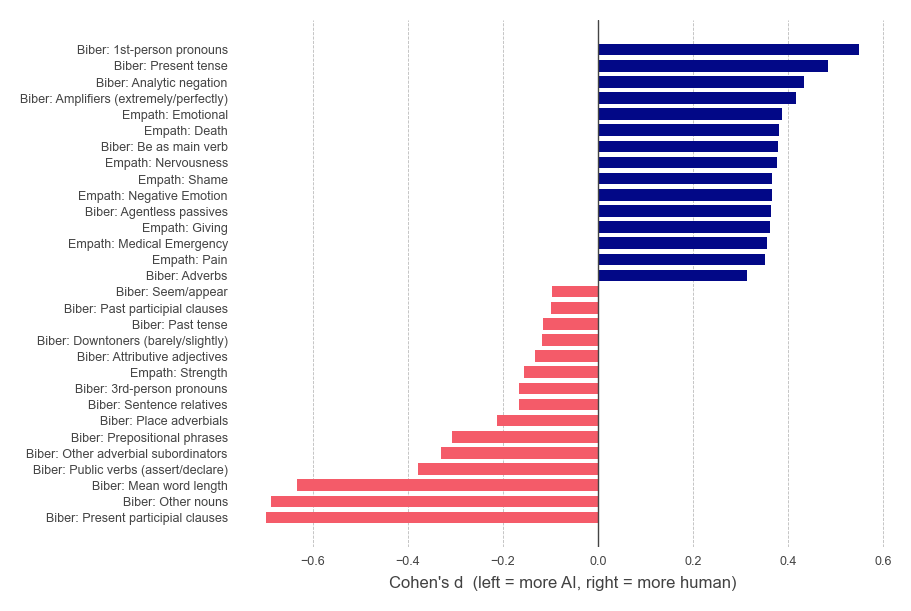

Saved plots/sci_fund_real_human_vs_ai_profile.pdf


In [8]:
####################
# Linguistic features and human-vs-AI classifier
####################
# Shared with the other study: the analysis lives in src/linguistic.py so both notebooks
# run identical code. That module's docstring lists the files it writes.

import sys
from pathlib import Path

ROOT = Path.cwd().parent
for path in (str(ROOT), str(ROOT / "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import pandas as pd
from helpers import make_aesthetic
from linguistic import run_features

TABLE_EXPORT = Path("tables")
FIGURE_EXPORT = Path("plots")
STUDY_STEM = Path.cwd().name

make_aesthetic(smallest_font_size=9, with_ticks=True)

feature_table, cv_all = run_features(
    pd.read_csv("data/clean/analysis_data.csv"),
    TABLE_EXPORT, FIGURE_EXPORT, STUDY_STEM,
)

## Keyness

**Output:** `sci_fund_real_human_ai_keyness.csv`

**Computation:** log-odds with a Dirichlet prior, human versus AI text.

Human docs: 285  |  AI docs: 285


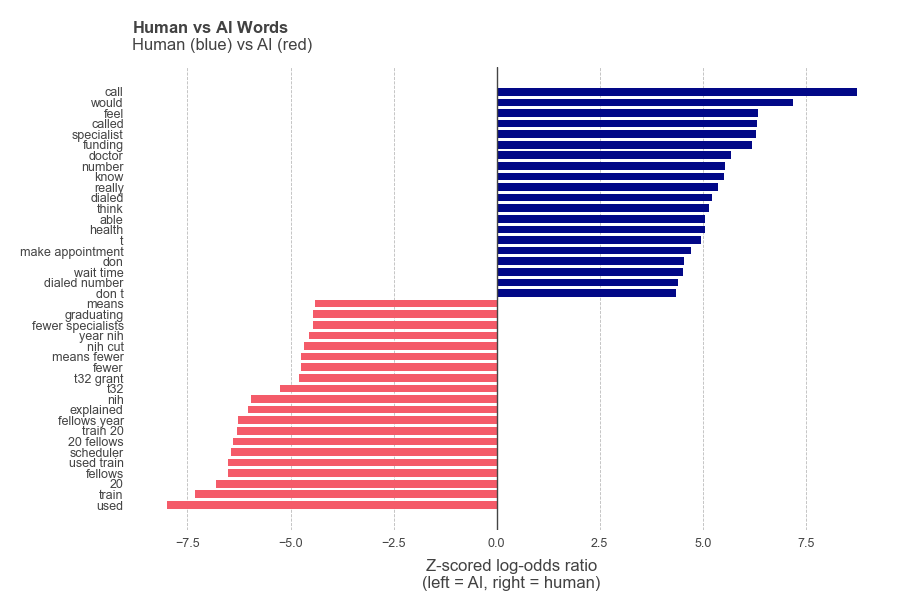

Saved plots/sci_fund_real_logodds_human_vs_ai.pdf


In [9]:
####################
# Keyness: which words distinguish human from AI text
####################
# Shared with the other study; see src/linguistic.py.

import sys
from pathlib import Path

ROOT = Path.cwd().parent
for path in (str(ROOT), str(ROOT / "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import pandas as pd
from helpers import make_aesthetic, make_bold
from linguistic import run_keyness

TABLE_EXPORT = Path("tables")
FIGURE_EXPORT = Path("plots")
STUDY_STEM = Path.cwd().name

make_aesthetic(smallest_font_size=9, with_ticks=True)

keyness_results = run_keyness(
    pd.read_csv("data/clean/analysis_data.csv"),
    TABLE_EXPORT, FIGURE_EXPORT, STUDY_STEM, make_bold,
)

# Heterogeneous treatment effects

**Outputs:** `sci_fund_real_causal_forest_blp.csv`, and `blp_*.pdf` and `loess_*.pdf` for each outcome and comparison (Supplementary Information)

**Computation:** exports the analysis sample for each comparison, then runs the causal forests in `hte_grf.R`.

In [10]:
# ─────────────────────────────────────────────
# FLAG: EXCLUSION — Heterogeneous treatment effects (HTE / GRF)
# Applied on top of main sample
#   1. Gender restricted to Male/Female (non-binary excluded as moderator
#      variable would be collinear with small cell sizes)
#   2. Listwise deletion on all moderator columns (dropna at end)
#   Treat vs placebo also requires ac_* engagement cols — participants
#   whose journal could not be matched have these set to NaN and are
#   excluded from that contrast's HTE export.
# ─────────────────────────────────────────────

BASE_X_COLS = [
    "familiar", "age",
    "mi_index", "transport_index",
    "iri_fa", "iri_pc", "iri_pd",
    "rw_journal", "rw_write",
    "educ_num", "income_num", "ideology_num",
    "ai_attitude_index",
]

ENGAGEMENT_COLS = ['ac_received', 'ac_acceptance_rate', 'ac_total_words', 'ac_prop_ai_words']

SYS_COLS = ["sys_easy", "sys_fun", "sys_helped", "sys_prompt_helped",
            "sys_tailored", "sys_realistic", "sys_agency_1"]

# treat vs placebo: base + engagement + system ratings
# treat vs vignette: base only (no autocomplete or sys ratings)
CONTRAST_X_COLS = {
    ("treat", "placebo"):  BASE_X_COLS + ENGAGEMENT_COLS + SYS_COLS,
    ("treat", "vignette"): BASE_X_COLS,
}

OUTCOMES  = ["closeness_index", "attitude_index"]
TREATMENT = "treat_status"
CONTRASTS = [("treat", "placebo"), ("treat", "vignette")]

keep_mask = (
    df["demo_gender"].isin(["Male", "Female"]) &
df[TREATMENT].isin(["treat", "placebo", "vignette"])
)

df_filtered = df.loc[keep_mask].copy()
df_filtered["age"] = pd.to_numeric(df_filtered["age"], errors="coerce")

for t1, t0 in CONTRASTS:
    x_cols    = CONTRAST_X_COLS[(t1, t0)]
    keep_cols = x_cols + OUTCOMES + [TREATMENT, "demo_gender"]

    missing = [c for c in keep_cols if c not in df_filtered.columns]
    if missing:
        print(f"WARNING: {t1} vs {t0} missing cols: {missing}")
        continue

    df_r = df_filtered[
        df_filtered[TREATMENT].isin([t1, t0])
    ][keep_cols].copy().dropna()

    print(f"\n{t1} vs {t0}: {len(df_r)} rows")
    print(df_r[TREATMENT].value_counts())
    print(f"Moderators ({len(x_cols)}): {x_cols}")

    fname = f"tables/hte_data_{t1}_vs_{t0}.csv"
    df_r.to_csv(fname, index=False)
    print(f"Saved: {fname}")


treat vs placebo: 644 rows
treat_status
placebo    327
treat      317
Name: count, dtype: int64
Moderators (24): ['familiar', 'age', 'mi_index', 'transport_index', 'iri_fa', 'iri_pc', 'iri_pd', 'rw_journal', 'rw_write', 'educ_num', 'income_num', 'ideology_num', 'ai_attitude_index', 'ac_received', 'ac_acceptance_rate', 'ac_total_words', 'ac_prop_ai_words', 'sys_easy', 'sys_fun', 'sys_helped', 'sys_prompt_helped', 'sys_tailored', 'sys_realistic', 'sys_agency_1']
Saved: tables/hte_data_treat_vs_placebo.csv

treat vs vignette: 638 rows
treat_status
treat       320
vignette    318
Name: count, dtype: int64
Moderators (13): ['familiar', 'age', 'mi_index', 'transport_index', 'iri_fa', 'iri_pc', 'iri_pd', 'rw_journal', 'rw_write', 'educ_num', 'income_num', 'ideology_num', 'ai_attitude_index']
Saved: tables/hte_data_treat_vs_vignette.csv


In [1]:
"""
Name: Joshua Ashkinaze

Date: 2026-09-08

Description: Re-run the existing causal-forest analysis and export its results.

Inputs:
- tables/hte_data_treat_vs_placebo.csv and tables/hte_data_treat_vs_vignette.csv.
- The original study-specific R analysis.

Outputs:
- Original BLP and CATE/LOESS plots and prediction tables.
- ../sci_fund_real/tables/STUDY_causal_forest_blp.csv and run metadata.
"""
from pathlib import Path
import subprocess
import pandas as pd

STUDY = Path.cwd().name
R_SCRIPT = "hte_grf.R"
clean = pd.read_csv("data/clean/analysis_data.csv")
# ac_prop_ai_words exceeds 1 for a handful of participants; cap it so the
# proportion is well defined wherever it is used downstream.
if "ac_prop_ai_words" in clean.columns:
    clean["ac_prop_ai_words"] = clean["ac_prop_ai_words"].clip(upper=1)
clean["treat_status"] = clean.treat_status.replace({"control": "vignette"})
match_columns = ["treat_status", "closeness_index", "attitude_index"]
for control in ["placebo", "vignette"]:
    exported = pd.read_csv(f"tables/hte_data_treat_vs_{control}.csv")
    original_rows = pd.MultiIndex.from_frame(clean[match_columns].round(8))
    exported_rows = pd.MultiIndex.from_frame(exported[match_columns].round(8))
    assert exported_rows.isin(original_rows).all(), "HTE outcomes do not match the main sample."
    print(control, len(exported), exported.treat_status.value_counts().to_dict())

r_code = r'''
source("R_SCRIPT")
export_rows <- list()
for (control in names(results)) {
  for (outcome in OUTCOMES) {
    result <- results[[control]][[outcome]]
    coefficients <- result$blp
    plot_predictions <- as.data.frame(result$X_sub)
    plot_predictions$cate <- predict(result$forest)$predictions
    write.csv(plot_predictions, sprintf("tables/cate_plot_preds_treat_vs_%s_%s.csv", control, outcome), row.names = FALSE)
    export_rows[[paste(control, outcome)]] <- data.frame(
      control = control, outcome = outcome,
      term = rownames(coefficients),
      estimate = coefficients[, "Estimate"],
      se = coefficients[, "Std. Error"],
      statistic = coefficients[, "t value"],
      p = coefficients[, "Pr(>|t|)"],
      ci_lower = coefficients[, "Estimate"] - 1.96 * coefficients[, "Std. Error"],
      ci_upper = coefficients[, "Estimate"] + 1.96 * coefficients[, "Std. Error"],
      n = nrow(result$X_sub),
      n_treat = sum(result$forest$W.orig == 1),
      n_control = sum(result$forest$W.orig == 0)
    )
  }
}
write.csv(do.call(rbind, export_rows),
          "../sci_fund_real/tables/STUDY_causal_forest_blp.csv", row.names = FALSE)
capture.output(sessionInfo(), file = "../sci_fund_real/tables/STUDY_causal_forest_session.txt")
'''
r_code = r_code.replace("R_SCRIPT", R_SCRIPT).replace("STUDY", STUDY)
run = subprocess.run(["Rscript", "-e", r_code],
                     text=True, capture_output=True)
print(run.stdout)
print(run.stderr)
run.check_returncode()


placebo 644 {'placebo': 327, 'treat': 317}
vignette 638 {'treat': 320, 'vignette': 318}


Working directory: /Users/jashkina/Documents/locresearch/LocResearch/asif_studies/sci_fund_real 

--- Loading: tables/hte_data_treat_vs_placebo.csv ---
Rows: 644 

placebo   treat 
    327     317 
After dropna: 644 

Fitting: closeness_index | treat vs placebo
  n=644, T=1(treat)=317, T=0(placebo)=327

Fitting: attitude_index | treat vs placebo
  n=644, T=1(treat)=317, T=0(placebo)=327

--- Loading: tables/hte_data_treat_vs_vignette.csv ---
Rows: 638 

   treat vignette 
     320      318 
After dropna: 638 

Fitting: closeness_index | treat vs vignette
  n=638, T=1(treat)=320, T=0(vignette)=318

Fitting: attitude_index | treat vs vignette
  n=638, T=1(treat)=320, T=0(vignette)=318
Saved predictions: tables/cate_preds_treat_vs_placebo_closeness_index.csv 
Saved predictions: tables/cate_preds_treat_vs_placebo_attitude_index.csv 
Saved predictions: tables/cate_preds_treat_vs_vignette_closeness_index.csv 
Saved predictions: tables/cate_preds_treat_vs_vignette_attitude_index.csv 

Outcome